Dataset Shape: (1200, 8)

First 5 Rows:


,VisitorID,Variant,Timestamp,Device,TrafficSource,CheckoutStarted,Converted,OrderValueINR
0,VIS-00001,A,2026-07-10T14:33:00,Tablet,Paid,Yes,No,0
1,VIS-00002,B,2026-07-01T13:41:00,Tablet,Paid,No,No,0
2,VIS-00003,A,2026-07-18T04:55:00,Tablet,Paid,No,No,0
3,VIS-00004,B,2026-07-17T22:45:00,Desktop,Paid,No,No,0
4,VIS-00005,A,2026-07-17T23:44:00,Mobile,Direct,Yes,No,0



Missing Values:
VisitorID          0
Variant            0
Timestamp          0
Device             0
TrafficSource      0
CheckoutStarted    0
Converted          0
OrderValueINR      0
dtype: int64

Variant Distribution:
Variant
A    600
B    600
Name: count, dtype: int64

Conversion Distribution:
Converted
No     1072
Yes     128
Name: count, dtype: int64

DATA INTEGRITY CHECKS
Duplicate VisitorIDs: 0
Converted=Yes but OrderValue=0: 0
Converted=No but OrderValue>0: 0
Converted=Yes but CheckoutStarted=No: 0

SUMMARY BY VARIANT


,Visitors,Checkout_Starts,Conversions,Revenue,Conversion_Rate,Checkout_Rate,Revenue_per_Visitor
Variant,,,,,,,
A,600,186,57,8093,9.50,31.00,13.49
B,600,194,71,10679,11.83,32.33,17.80


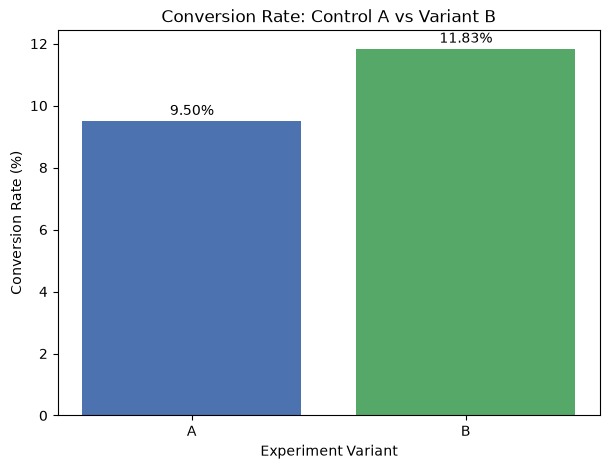

Null Hypothesis (H0):
Control A and Variant B have equal conversion rates (pA = pB).

Alternative Hypothesis (H1):
Control A and Variant B have different conversion rates (pA != pB).

Significance Level (alpha): 0.05

Control A: 57/600 conversions = 9.50%
Variant B: 71/600 conversions = 11.83%

TWO-SAMPLE Z-TEST
Z Statistic: 1.3092
P-value: 0.1905
Result: No statistically significant difference.

CHI-SQUARE TEST
Chi-square Statistic: 1.7141
P-value: 0.1905
Degrees of Freedom: 1
Result: No statistically significant association.

EFFECT SIZE
Absolute Difference: 2.33 percentage points
Relative Conversion Lift: 24.56 %
95% Confidence Interval: -1.16 to 5.82 percentage points
Cohen's h: 0.0757 (0.2 = small, 0.5 = medium, 0.8 = large)

SAMPLE SIZE CHECK
Required visitors per variant (80% power): 2744
Current visitors per variant: 600

REVENUE ANALYSIS
Control A Revenue: ₹ 8,093
Variant B Revenue: ₹ 10,679
Control A Average Order Value: ₹ 141.98
Variant B Average Order Value: ₹ 150.41

FINAL

In [14]:
# ============================================================
# A/B TESTING & HYPOTHESIS TESTING - CHECKOUT EXPERIMENT
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2_contingency

# ============================================================
# 1. LOAD DATA
# ============================================================
df = pd.read_csv(r"C:\Users\soulx\Downloads\checkout_ab_test_v2 (1).csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nVariant Distribution:")
print(df["Variant"].value_counts())

print("\nConversion Distribution:")
print(df["Converted"].value_counts())

# ============================================================
# 2. DATA INTEGRITY CHECKS
# ============================================================
print("\nDATA INTEGRITY CHECKS")
print("Duplicate VisitorIDs:", df["VisitorID"].duplicated().sum())
print("Converted=Yes but OrderValue=0:",
      ((df["Converted"] == "Yes") & (df["OrderValueINR"] == 0)).sum())
print("Converted=No but OrderValue>0:",
      ((df["Converted"] == "No") & (df["OrderValueINR"] > 0)).sum())
print("Converted=Yes but CheckoutStarted=No:",
      ((df["Converted"] == "Yes") & (df["CheckoutStarted"] == "No")).sum())

# ============================================================
# 3. SUMMARY TABLE
# ============================================================
summary = df.groupby("Variant").agg(
    Visitors=("VisitorID", "count"),
    Checkout_Starts=("CheckoutStarted", lambda x: (x == "Yes").sum()),
    Conversions=("Converted", lambda x: (x == "Yes").sum()),
    Revenue=("OrderValueINR", "sum")
)
summary["Conversion_Rate"] = summary["Conversions"] / summary["Visitors"] * 100
summary["Checkout_Rate"] = summary["Checkout_Starts"] / summary["Visitors"] * 100
summary["Revenue_per_Visitor"] = summary["Revenue"] / summary["Visitors"]

print("\nSUMMARY BY VARIANT")
display(summary.round(2))

# ============================================================
# 4. VISUALISATION
# ============================================================
plt.figure(figsize=(7, 5))
plt.bar(summary.index, summary["Conversion_Rate"], color=["#4C72B0", "#55A868"])
plt.title("Conversion Rate: Control A vs Variant B")
plt.xlabel("Experiment Variant")
plt.ylabel("Conversion Rate (%)")
for i, value in enumerate(summary["Conversion_Rate"]):
    plt.text(i, value + 0.2, f"{value:.2f}%", ha="center")
plt.show()

# ============================================================
# 5. HYPOTHESES
# ============================================================
print("Null Hypothesis (H0):")
print("Control A and Variant B have equal conversion rates (pA = pB).")
print("\nAlternative Hypothesis (H1):")
print("Control A and Variant B have different conversion rates (pA != pB).")
print("\nSignificance Level (alpha): 0.05")

# ============================================================
# 6. SAMPLE SIZES AND CONVERSION RATES
# ============================================================
nA = int(summary.loc["A", "Visitors"])
nB = int(summary.loc["B", "Visitors"])
xA = int(summary.loc["A", "Conversions"])
xB = int(summary.loc["B", "Conversions"])

pA = xA / nA   # fraction (0 to 1)
pB = xB / nB

print(f"\nControl A: {xA}/{nA} conversions = {pA*100:.2f}%")
print(f"Variant B: {xB}/{nB} conversions = {pB*100:.2f}%")

# ============================================================
# 7. TWO-SAMPLE Z-TEST FOR PROPORTIONS
# ============================================================
pooled = (xA + xB) / (nA + nB)
se = np.sqrt(pooled * (1 - pooled) * (1 / nA + 1 / nB))
z = (pB - pA) / se
p_value = 2 * (1 - norm.cdf(abs(z)))

print("\nTWO-SAMPLE Z-TEST")
print("Z Statistic:", round(z, 4))
print("P-value:", round(p_value, 4))
if p_value < 0.05:
    print("Result: Statistically significant difference.")
else:
    print("Result: No statistically significant difference.")

# ============================================================
# 8. CHI-SQUARE TEST OF INDEPENDENCE
# ============================================================
table = [[xA, nA - xA],
         [xB, nB - xB]]

chi2, chi_p, dof, expected = chi2_contingency(table, correction=False)

print("\nCHI-SQUARE TEST")
print("Chi-square Statistic:", round(chi2, 4))
print("P-value:", round(chi_p, 4))
print("Degrees of Freedom:", dof)
if chi_p < 0.05:
    print("Result: Statistically significant association.")
else:
    print("Result: No statistically significant association.")

# ============================================================
# 9. EFFECT SIZE AND CONFIDENCE INTERVAL
# ============================================================
difference = pB - pA
relative_lift = difference / pA * 100

se_ci = np.sqrt(pA * (1 - pA) / nA + pB * (1 - pB) / nB)
lower = difference - 1.96 * se_ci
upper = difference + 1.96 * se_ci

# Cohen's h (standardised effect size for proportions)
h = 2 * np.arcsin(np.sqrt(pB)) - 2 * np.arcsin(np.sqrt(pA))

print("\nEFFECT SIZE")
print("Absolute Difference:", round(difference * 100, 2), "percentage points")
print("Relative Conversion Lift:", round(relative_lift, 2), "%")
print("95% Confidence Interval:", round(lower * 100, 2), "to",
      round(upper * 100, 2), "percentage points")
print("Cohen's h:", round(h, 4), "(0.2 = small, 0.5 = medium, 0.8 = large)")

# ============================================================
# 10. REQUIRED SAMPLE SIZE (80% POWER)
# ============================================================
alpha, power = 0.05, 0.80
z_alpha = norm.ppf(1 - alpha / 2)
z_beta = norm.ppf(power)
n_required = ((z_alpha + z_beta) ** 2 *
              (pA * (1 - pA) + pB * (1 - pB))) / (pB - pA) ** 2
n_required = int(np.ceil(n_required))

print("\nSAMPLE SIZE CHECK")
print("Required visitors per variant (80% power):", n_required)
print("Current visitors per variant:", nA)

# ============================================================
# 11. REVENUE ANALYSIS
# ============================================================
revenueA = int(df.loc[df["Variant"] == "A", "OrderValueINR"].sum())
revenueB = int(df.loc[df["Variant"] == "B", "OrderValueINR"].sum())

aovA = revenueA / xA if xA > 0 else 0
aovB = revenueB / xB if xB > 0 else 0

print("\nREVENUE ANALYSIS")
print("Control A Revenue: ₹", f"{revenueA:,}")
print("Variant B Revenue: ₹", f"{revenueB:,}")
print("Control A Average Order Value: ₹", round(aovA, 2))
print("Variant B Average Order Value: ₹", round(aovB, 2))

# ============================================================
# 12. FINAL REPORT AND EXECUTIVE DECISION MEMO
# ============================================================
print("\nFINAL A/B TEST REPORT")
print("---------------------")
print(f"Control A Conversion Rate: {pA*100:.2f}%")
print(f"Variant B Conversion Rate: {pB*100:.2f}%")
print(f"Absolute Difference: {difference*100:.2f} pp")
print(f"Relative Lift: {relative_lift:.2f}%")
print(f"95% CI: {lower*100:.2f} to {upper*100:.2f} pp")
print(f"Z = {z:.4f}, P-value = {p_value:.4f}, Cohen's h = {h:.3f}")

print("\n" + "=" * 60)
print("EXECUTIVE DECISION MEMO")
print("=" * 60)
print("To: Product & Growth Leadership")
print("Subject: Checkout A/B Test - Launch Variant B or Keep Control?\n")

print("Summary:")
print(f"Variant B converted at {pB*100:.2f}% versus {pA*100:.2f}% for Control A "
      f"(+{difference*100:.2f} pp, {relative_lift:.1f}% relative lift) across "
      f"{nA + nB} visitors.")
print(f"Revenue was ₹{revenueB:,} for B vs ₹{revenueA:,} for A; "
      f"average order value was ₹{aovB:.0f} vs ₹{aovA:.0f}.\n")

print("Statistical evidence:")
print(f"- Two-proportion z-test p = {p_value:.4f} (chi-square agrees); threshold is 0.05.")
print(f"- 95% CI for the difference is {lower*100:.2f} to {upper*100:.2f} pp, "
      f"{'which includes zero.' if lower < 0 < upper else 'which excludes zero.'}")
print(f"- Effect size is small (Cohen's h = {h:.2f}).\n")

if p_value < 0.05 and pB > pA:
    print("Decision: LAUNCH Variant B.")
    print("Rationale: the lift is statistically significant and positive, "
          "so B outperforms Control A.")
elif p_value < 0.05 and pB < pA:
    print("Decision: KEEP CONTROL A.")
    print("Rationale: Variant B performed significantly worse than Control.")
else:
    print("Decision: KEEP CONTROL A for now (do not launch B yet).")
    print("Rationale: the uplift is not statistically distinguishable from "
          "random variation at the current sample size. To reliably detect a "
          f"lift of this size, about {n_required} visitors per variant are "
          f"needed (currently {nA}).")
    print("Next step: extend the test to the required sample size, then "
          "re-run this analysis before making a launch decision.")